In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

In [2]:
# 1. Configuración y reproducibilidad
SEED = 123
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


In [3]:
# 2. Descarga automática del dataset (37 razas de perros y gatos)
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

print("Descargando dataset Oxford-IIIT Pet...")
train_dataset = datasets.OxfordIIITPet(
    root="./data", split="trainval", transform=transform, download=True
)
full_test_dataset = datasets.OxfordIIITPet(
    root="./data", split="test", transform=transform, download=True
)
class_names = train_dataset.classes  # Nombres reales de las 37 razas
num_classes = len(class_names)

Descargando dataset Oxford-IIIT Pet...


In [4]:
# Dividimos test en: Calibración (1,500 imágenes) y Prueba final (1,169 imágenes)
cal_size = 1_500
test_size = len(full_test_dataset) - cal_size
cal_dataset, test_dataset = random_split(
    full_test_dataset,
    [cal_size, test_size],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
cal_loader = DataLoader(cal_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [5]:
# 3. Transfer Learning con ResNeSt-50
print("Cargando ResNeSt-50 preentrenado...")
model = timm.create_model(
    "resnest50d", pretrained=True, num_classes=num_classes
)

# Congelamos la red base y entrenamos solo la cabeza clasificadora (~40 seg en GPU)
for param in model.parameters():
  param.requires_grad = False
for param in model.get_classifier().parameters():
  param.requires_grad = True

model = model.to(device)
optimizer = torch.optim.Adam(model.get_classifier().parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 3
print(f"Iniciando Transfer Learning ({EPOCHS} épocas)...")
for epoch in range(EPOCHS):
  model.train()
  running_loss = 0.0
  for imgs, labels in train_loader:
    imgs, labels = imgs.to(device), labels.to(device)
    optimizer.zero_grad()
    outputs = model(imgs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item() * imgs.size(0)
  print(
      f"Época {epoch+1}/{EPOCHS} - Loss:"
      f" {running_loss/len(train_dataset):.4f}"
  )

Cargando ResNeSt-50 preentrenado...
Iniciando Transfer Learning (3 épocas)...
Época 1/3 - Loss: 1.6819
Época 2/3 - Loss: 0.4700
Época 3/3 - Loss: 0.2829


In [6]:
@torch.no_grad()
def get_probs_and_labels(loader):
  model.eval()
  all_probs, all_labels = [], []
  for imgs, labels in loader:
    imgs = imgs.to(device)
    probs = F.softmax(model(imgs), dim=1).cpu().numpy()
    all_probs.append(probs)
    all_labels.append(labels.numpy())
  return np.vstack(all_probs), np.concatenate(all_labels)

In [7]:
# 4. Calibración con Split Conformal Prediction
ALPHA = 0.10  # Cobertura del 90% (1 - ALPHA)
target_coverage = 1.0 - ALPHA
probs_cal, y_cal = get_probs_and_labels(cal_loader)

# Puntaje de no conformidad: 1 - probabilidad asignada a la clase verdadera
n_cal = len(y_cal)
cal_scores = 1.0 - probs_cal[np.arange(n_cal), y_cal]

# Cuantil ajustado por muestra finita
q_level = min(np.ceil((n_cal + 1) * target_coverage) / n_cal, 1.0)
q_hat = np.quantile(cal_scores, q_level, method="higher")
prob_threshold = 1.0 - q_hat

print(
    f"\n--- Resultados de Calibración (Cobertura objetivo: {target_coverage:.0%})"
    " ---"
)
print(
    f"Cuantil q_hat: {q_hat:.4f} -> Umbral mínimo de probabilidad:"
    f" {prob_threshold:.2%}"
)


--- Resultados de Calibración (Cobertura objetivo: 90%) ---
Cuantil q_hat: 0.7429 -> Umbral mínimo de probabilidad: 25.71%


In [8]:
# 5. Evaluación e Indicadores de Cobertura en el conjunto de prueba (Test)
probs_test, y_test = get_probs_and_labels(test_loader)
n_test = len(y_test)
prediction_sets = [np.where(p >= prob_threshold)[0] for p in probs_test]

hits = np.array([y_test[i] in prediction_sets[i] for i in range(n_test)])
set_sizes = np.array([len(s) for s in prediction_sets])
max_probs = np.max(probs_test, axis=1)

# Indicadores globales y error estándar finito
empirical_coverage = np.mean(hits)
coverage_gap = empirical_coverage - target_coverage
se_coverage = np.sqrt(target_coverage * ALPHA / n_test)

# Desglose por cardinalidad del conjunto
empty_mask = set_sizes == 0
singleton_mask = set_sizes == 1
multi_mask = set_sizes >= 2

# Indicadores por categoría (Cobertura condicional y longitud de intervalo)
cat_coverage = np.zeros(num_classes)
cat_size_min = np.zeros(num_classes)
cat_size_median = np.zeros(num_classes)
cat_size_mean = np.zeros(num_classes)
cat_size_max = np.zeros(num_classes)

for c in range(num_classes):
  idx_c = y_test == c
  cat_coverage[c] = np.mean(hits[idx_c])
  sizes_c = set_sizes[idx_c]
  cat_size_min[c] = np.min(sizes_c)
  cat_size_median[c] = np.median(sizes_c)
  cat_size_mean[c] = np.mean(sizes_c)
  cat_size_max[c] = np.max(sizes_c)

cats_meeting_target = np.mean(cat_coverage >= target_coverage)

print("\n" + "=" * 62)
print("INDICADORES DE COBERTURA Y EFICIENCIA EN TEST")
print("=" * 62)
print(
    f"Cobertura empírica global : {empirical_coverage:.2%} (Objetivo:"
    f" {target_coverage:.0%} | Dif: {coverage_gap:+.2%})"
)
print(
    "Rango esperado por muestra: "
    f"[{target_coverage - 1.96*se_coverage:.2%},"
    f" {target_coverage + 1.96*se_coverage:.2%}] (95% IC teórico)"
)
print(
    f"Longitud del intervalo    : Media = {np.mean(set_sizes):.2f} | "
    f"Mediana = {np.median(set_sizes):.1f} | "
    f"Min = {np.min(set_sizes)} | Max = {np.max(set_sizes)}"
)
print("-" * 62)
print(
    f"Conjuntos vacíos (size=0) : {np.mean(empty_mask):.2%}"
    f" ({np.sum(empty_mask)} imgs) -> Cobertura: 0.00%"
)
print(
    f"Predicción única (size=1) : {np.mean(singleton_mask):.2%}"
    f" ({np.sum(singleton_mask)} imgs) -> Cobertura:"
    f" {np.mean(hits[singleton_mask]):.2%}"
)
print(
    f"Conjunto múltiple (size≥2): {np.mean(multi_mask):.2%}"
    f" ({np.sum(multi_mask)} imgs) -> Cobertura:"
    f" {np.mean(hits[multi_mask]):.2%}"
)
print("-" * 62)
print(
    f"Cobertura por categoría   : Media = {np.mean(cat_coverage):.2%} | "
    f"Mín = {np.min(cat_coverage):.2%}"
    f" ({class_names[np.argmin(cat_coverage)]}) | "
    f"Máx = {np.max(cat_coverage):.2%}"
    f" ({class_names[np.argmax(cat_coverage)]})"
)
print(
    f"Categorías ≥ {target_coverage:.0%} cobertura:"
    f" {np.sum(cat_coverage >= target_coverage)}/{num_classes}"
    f" ({cats_meeting_target:.1%})"
)
print("=" * 62 + "\n")


INDICADORES DE COBERTURA Y EFICIENCIA EN TEST
Cobertura empírica global : 90.13% (Objetivo: 90% | Dif: +0.13%)
Rango esperado por muestra: [88.74%, 91.26%] (95% IC teórico)
Longitud del intervalo    : Media = 1.10 | Mediana = 1.0 | Min = 0 | Max = 3
--------------------------------------------------------------
Conjuntos vacíos (size=0) : 2.12% (46 imgs) -> Cobertura: 0.00%
Predicción única (size=1) : 86.21% (1870 imgs) -> Cobertura: 92.03%
Conjunto múltiple (size≥2): 11.66% (253 imgs) -> Cobertura: 92.49%
--------------------------------------------------------------
Cobertura por categoría   : Media = 90.08% | Mín = 54.69% (American Pit Bull Terrier) | Máx = 100.00% (English Setter)
Categorías ≥ 90% cobertura: 25/37 (67.6%)



# GRÁFICOS


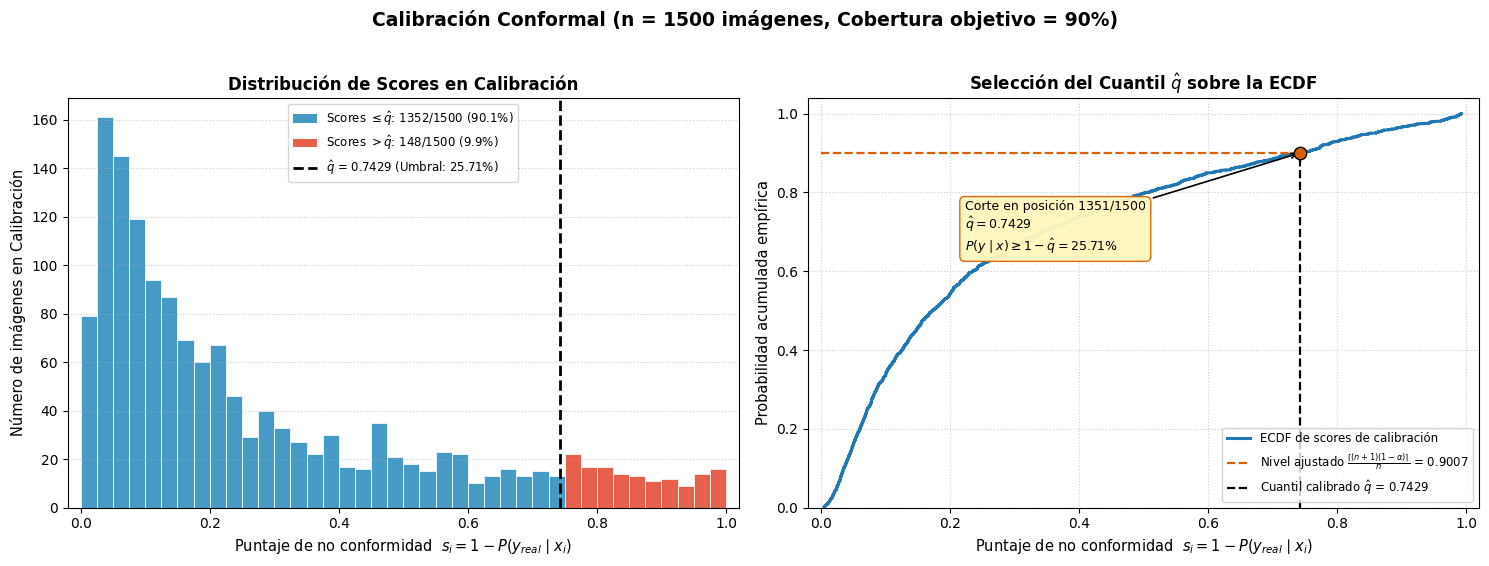

In [22]:
from matplotlib.patches import Patch

sorted_scores = np.sort(cal_scores)
ecdf_y = np.arange(1, n_cal + 1) / n_cal
k_idx = int(np.ceil((n_cal + 1) * target_coverage))
included_cal = np.sum(cal_scores <= q_hat)

fig, (ax_hist, ax_ecdf) = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel izquierdo: Histograma de puntajes de no conformidad s_i = 1 - P(y_real | x_i)
bins_cal = np.linspace(0.0, 1.0, 41)
counts, bin_edges, patches = ax_hist.hist(
    cal_scores, bins=bins_cal, edgecolor="white", linewidth=0.6, alpha=0.88
)

for patch, left_edge, right_edge in zip(patches, bin_edges[:-1], bin_edges[1:]):
  bin_mid = 0.5 * (left_edge + right_edge)
  if bin_mid <= q_hat:
    patch.set_facecolor("#2b8cbe")  # Región incluida en el set conformal
  else:
    patch.set_facecolor("#e34a33")  # Tail de error permitido (<= alpha)

ax_hist.axvline(
    q_hat,
    color="black",
    linestyle="--",
    linewidth=2,
)

legend_elements = [
    Patch(
        facecolor="#2b8cbe",
        alpha=0.88,
        label=(
            f"Scores $\\leq \\hat{{q}}$: {included_cal}/{n_cal}"
            f" ({included_cal/n_cal:.1%})"
        ),
    ),
    Patch(
        facecolor="#e34a33",
        alpha=0.88,
        label=(
            f"Scores $> \\hat{{q}}$: {n_cal - included_cal}/{n_cal}"
            f" ({(n_cal - included_cal)/n_cal:.1%})"
        ),
    ),
    plt.Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"$\\hat{{q}}$ = {q_hat:.4f} (Umbral: {prob_threshold:.2%})",
    ),
]

ax_hist.set_xlabel(
    "Puntaje de no conformidad  $s_i = 1 - P(y_{real} \\mid x_i)$",
    fontsize=10.5,
)
ax_hist.set_ylabel("Número de imágenes en Calibración", fontsize=10.5)
ax_hist.set_title(
    "Distribución de Scores en Calibración",
    fontsize=12,
    fontweight="bold",
)
ax_hist.set_xlim(-0.02, 1.02)
ax_hist.grid(axis="y", linestyle=":", alpha=0.6)
ax_hist.legend(handles=legend_elements, loc="upper center", fontsize=8.5)

# Panel derecho: ECDF y cruce exacto del cuantil calibrado
ax_ecdf.step(
    sorted_scores,
    ecdf_y,
    where="post",
    color="#1f78b4",
    linewidth=2.2,
    label="ECDF de scores de calibración",
)

ax_ecdf.hlines(
    q_level,
    xmin=0,
    xmax=q_hat,
    color="#d95f02",
    linestyle="--",
    linewidth=1.6,
    label=(
        "Nivel ajustado"
        f" $\\frac{{\\lceil(n+1)(1-\\alpha)\\rceil}}{{n}}$ = {q_level:.4f}"
    ),
)
ax_ecdf.vlines(
    q_hat,
    ymin=0,
    ymax=q_level,
    color="black",
    linestyle="--",
    linewidth=1.6,
    label=f"Cuantil calibrado $\\hat{{q}}$ = {q_hat:.4f}",
)
ax_ecdf.scatter(
    [q_hat],
    [q_level],
    color="#d95f02",
    edgecolor="black",
    s=80,
    zorder=5,
)

# Anotación explicativa (con el símbolo % fuera de los signos $)
ax_ecdf.annotate(
    f"Corte en posición {k_idx}/{n_cal}\n"
    f"$\\hat{{q}} = {q_hat:.4f}$\n"
    f"$P(y\\mid x) \\geq 1 - \\hat{{q}} = {prob_threshold * 100:.2f}$%",
    xy=(q_hat, q_level),
    xytext=(max(0.08, q_hat - 0.52), max(0.35, q_level - 0.25)),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="#fff7bc",
        edgecolor="#d95f02",
        alpha=0.95,
    ),
)

ax_ecdf.set_xlabel(
    "Puntaje de no conformidad  $s_i = 1 - P(y_{real} \\mid x_i)$",
    fontsize=10.5,
)
ax_ecdf.set_ylabel("Probabilidad acumulada empírica", fontsize=10.5)
ax_ecdf.set_title(
    "Selección del Cuantil $\\hat{q}$ sobre la ECDF",
    fontsize=12,
    fontweight="bold",
)
ax_ecdf.set_xlim(-0.02, 1.02)
ax_ecdf.set_ylim(0, 1.04)
ax_ecdf.grid(True, linestyle=":", alpha=0.6)
ax_ecdf.legend(loc="lower right", fontsize=8.5)

plt.suptitle(
    f"Calibración Conformal (n = {n_cal} imágenes, Cobertura objetivo ="
    f" {target_coverage:.0%})",
    fontsize=13.5,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("conformal_calibracion_cuantil.png", dpi=200, bbox_inches="tight")
plt.show()

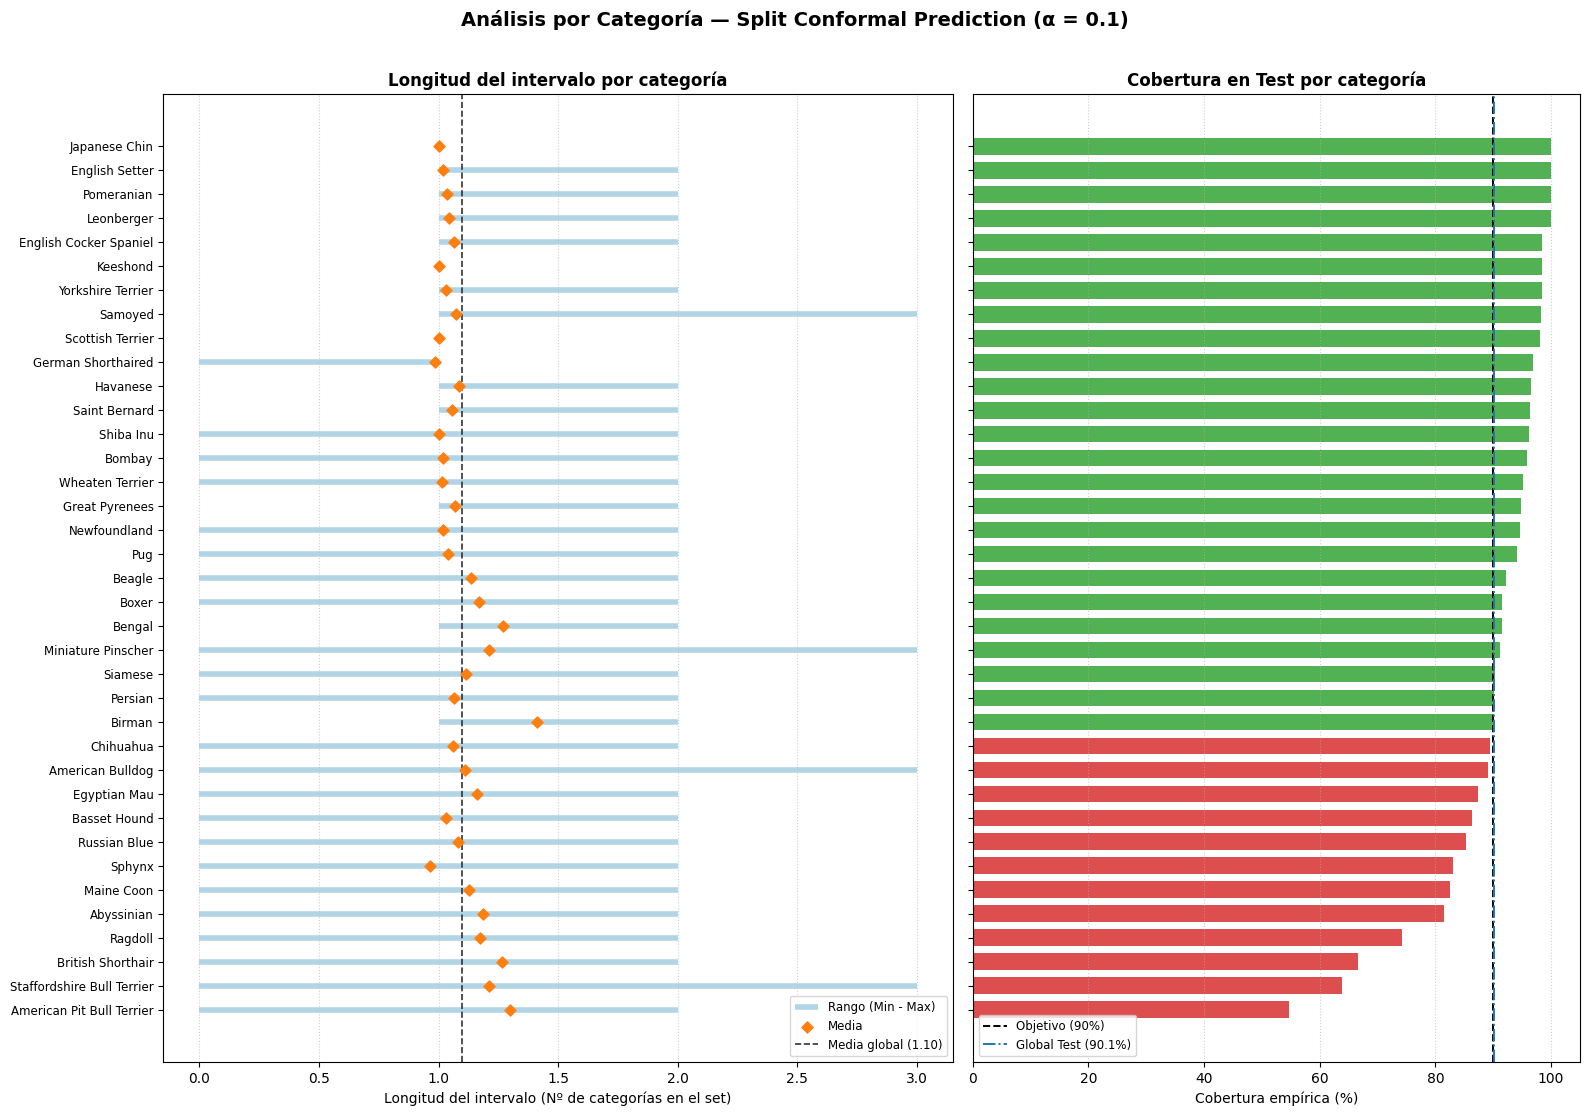

In [18]:
# 6. Gráficos de longitud del intervalo y cobertura

# --- GRÁFICO A: Longitud del intervalo y Cobertura por Categoría ---
# Ordenar de mayor a menor cobertura empírica (y desempatar por menor longitud media)
order = np.lexsort((cat_size_mean, -cat_coverage))
sorted_names = [class_names[i] for i in order]

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(16, 11),
    sharey=True,
    gridspec_kw={"width_ratios": [1.3, 1]},
)

y_pos = np.arange(num_classes)

ax1.hlines(
    y_pos,
    cat_size_min[order],
    cat_size_max[order],
    color="#9ecae1",
    linewidth=4,
    alpha=0.8,
    label="Rango (Min - Max)",
)
ax1.scatter(
    cat_size_mean[order],
    y_pos,
    color="#ff7f0e",
    marker="D",
    s=32,
    zorder=4,
    label="Media",
)
ax1.axvline(
    np.mean(set_sizes),
    color="#333333",
    linestyle="--",
    linewidth=1.2,
    label=f"Media global ({np.mean(set_sizes):.2f})",
)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(sorted_names, fontsize=8.5)
ax1.invert_yaxis()
ax1.set_xlabel("Longitud del intervalo (Nº de categorías en el set)", fontsize=10)
ax1.set_title("Longitud del intervalo por categoría", fontsize=12, fontweight="bold")
ax1.grid(axis="x", linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", fontsize=8.5)

cov_sorted = cat_coverage[order] * 100
bar_colors = [
    "#2ca02c" if c >= target_coverage * 100 else "#d62728" for c in cov_sorted
]

ax2.barh(y_pos, cov_sorted, color=bar_colors, alpha=0.82, height=0.7)
ax2.axvline(
    target_coverage * 100,
    color="black",
    linestyle="--",
    linewidth=1.4,
    label=f"Objetivo ({target_coverage:.0%})",
)
ax2.axvline(
    empirical_coverage * 100,
    color="#1f77b4",
    linestyle="-.",
    linewidth=1.4,
    label=f"Global Test ({empirical_coverage:.1%})",
)

ax2.set_xlim(0, 105)
ax2.set_xlabel("Cobertura empírica (%)", fontsize=10)
ax2.set_title("Cobertura en Test por categoría", fontsize=12, fontweight="bold")
ax2.grid(axis="x", linestyle=":", alpha=0.6)
ax2.legend(loc="lower left", fontsize=8.5)

plt.suptitle(
    f"Análisis por Categoría — Split Conformal Prediction (α = {ALPHA})",
    fontsize=14,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.savefig("conformal_analisis_categorias.png", dpi=200, bbox_inches="tight")
plt.show()

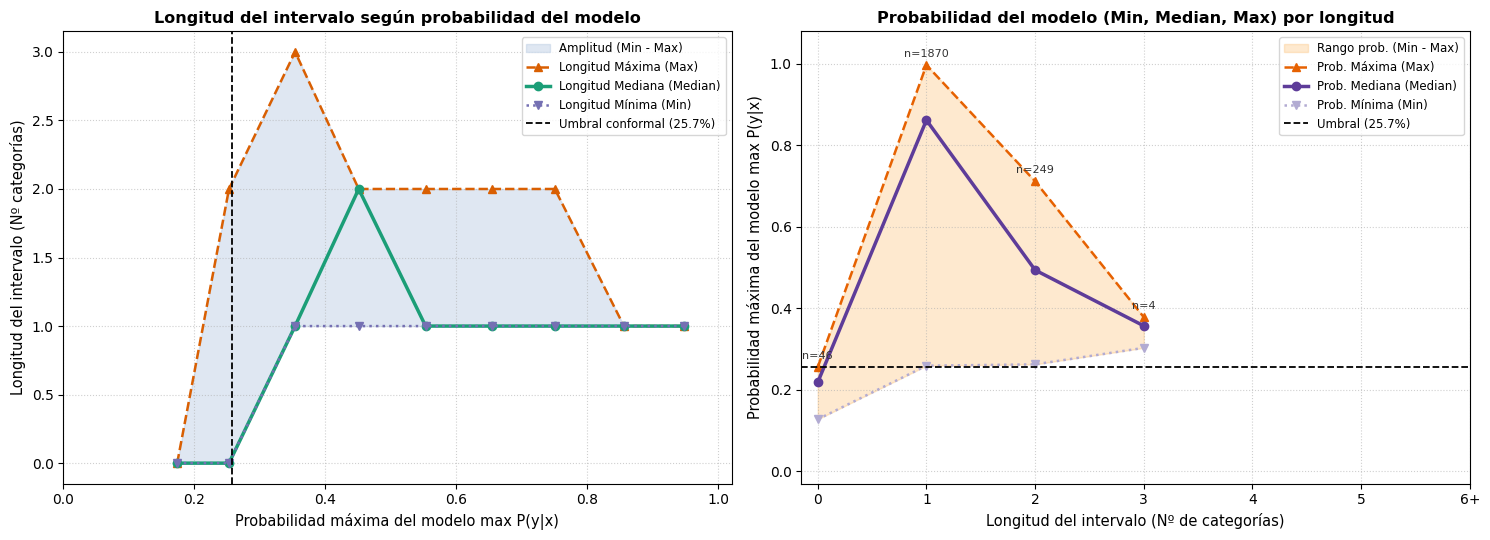

In [10]:
# --- GRÁFICO B: Longitud del intervalo según probabilidad del modelo (Min, Median, Max) ---
bins = np.linspace(0.0, 1.0, 11)
bin_centers, bin_mins, bin_medians, bin_maxs, bin_counts = [], [], [], [], []

for b_start, b_end in zip(bins[:-1], bins[1:]):
  if b_end == 1.0:
    mask_b = (max_probs >= b_start) & (max_probs <= b_end)
  else:
    mask_b = (max_probs >= b_start) & (max_probs < b_end)

  if np.any(mask_b):
    sizes_b = set_sizes[mask_b]
    bin_centers.append(np.mean(max_probs[mask_b]))
    bin_mins.append(np.min(sizes_b))
    bin_medians.append(np.median(sizes_b))
    bin_maxs.append(np.max(sizes_b))
    bin_counts.append(np.sum(mask_b))

bin_centers = np.array(bin_centers)
bin_mins = np.array(bin_mins)
bin_medians = np.array(bin_medians)
bin_maxs = np.array(bin_maxs)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(15, 5.5))

ax_left.fill_between(
    bin_centers,
    bin_mins,
    bin_maxs,
    color="#a6bddb",
    alpha=0.35,
    label="Amplitud (Min - Max)",
)
ax_left.plot(
    bin_centers,
    bin_maxs,
    marker="^",
    linestyle="--",
    color="#d95f02",
    linewidth=1.8,
    label="Longitud Máxima (Max)",
)
ax_left.plot(
    bin_centers,
    bin_medians,
    marker="o",
    linestyle="-",
    color="#1b9e77",
    linewidth=2.5,
    label="Longitud Mediana (Median)",
)
ax_left.plot(
    bin_centers,
    bin_mins,
    marker="v",
    linestyle=":",
    color="#7570b3",
    linewidth=1.8,
    label="Longitud Mínima (Min)",
)
ax_left.axvline(
    prob_threshold,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=f"Umbral conformal ({prob_threshold:.1%})",
)

ax_left.set_xlabel("Probabilidad máxima del modelo max P(y|x)", fontsize=10.5)
ax_left.set_ylabel("Longitud del intervalo (Nº categorías)", fontsize=10.5)
ax_left.set_title(
    "Longitud del intervalo según probabilidad del modelo",
    fontsize=11.5,
    fontweight="bold",
)
ax_left.set_xlim(0, 1.02)
ax_left.grid(True, linestyle=":", alpha=0.6)
ax_left.legend(loc="upper right", fontsize=8.5)

max_display_size = 6
size_labels = [str(s) for s in range(max_display_size)] + [f"{max_display_size}+"]
p_mins, p_medians, p_maxs, group_counts = [], [], [], []

for s in range(max_display_size + 1):
  mask_s = set_sizes == s if s < max_display_size else set_sizes >= max_display_size
  if np.any(mask_s):
    probs_s = max_probs[mask_s]
    p_mins.append(np.min(probs_s))
    p_medians.append(np.median(probs_s))
    p_maxs.append(np.max(probs_s))
    group_counts.append(np.sum(mask_s))
  else:
    p_mins.append(np.nan)
    p_medians.append(np.nan)
    p_maxs.append(np.nan)
    group_counts.append(0)

x_idx = np.arange(len(size_labels))
ax_right.fill_between(
    x_idx, p_mins, p_maxs, color="#fdb863", alpha=0.3, label="Rango prob. (Min - Max)"
)
ax_right.plot(
    x_idx, p_maxs, marker="^", linestyle="--", color="#e66101", linewidth=1.8, label="Prob. Máxima (Max)"
)
ax_right.plot(
    x_idx, p_medians, marker="o", linestyle="-", color="#5e3c99", linewidth=2.5, label="Prob. Mediana (Median)"
)
ax_right.plot(
    x_idx, p_mins, marker="v", linestyle=":", color="#b2abd2", linewidth=1.8, label="Prob. Mínima (Min)"
)
ax_right.axhline(
    prob_threshold,
    color="black",
    linestyle="--",
    linewidth=1.3,
    label=f"Umbral ({prob_threshold:.1%})",
)

for idx_x, cnt in enumerate(group_counts):
  if cnt > 0:
    ax_right.annotate(
        f"n={cnt}",
        (idx_x, p_maxs[idx_x]),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
        fontsize=8,
        color="#333333",
    )

ax_right.set_xticks(x_idx)
ax_right.set_xticklabels(size_labels)
ax_right.set_ylim(-0.03, 1.08)
ax_right.set_xlabel("Longitud del intervalo (Nº de categorías)", fontsize=10.5)
ax_right.set_ylabel("Probabilidad máxima del modelo max P(y|x)", fontsize=10.5)
ax_right.set_title(
    "Probabilidad del modelo (Min, Median, Max) por longitud",
    fontsize=11.5,
    fontweight="bold",
)
ax_right.grid(True, linestyle=":", alpha=0.6)
ax_right.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.savefig("conformal_longitud_vs_probabilidad.png", dpi=200, bbox_inches="tight")
plt.show()

=== 1. Certeza (1 clase) ===
Clase real: Great Pyrenees
Conjunto de predicción: ['Great Pyrenees'] (Tamaño: 1)

=== 2. Duda razonable (2-3 clases) ===
Clase real: Beagle
Conjunto de predicción: ['Basset Hound', 'Beagle'] (Tamaño: 2)

=== 3. Ambigüedad (set amplio) ===
Clase real: Miniature Pinscher
Conjunto de predicción: ['Miniature Pinscher', 'Staffordshire Bull Terrier', 'German Shorthaired'] (Tamaño: 3)



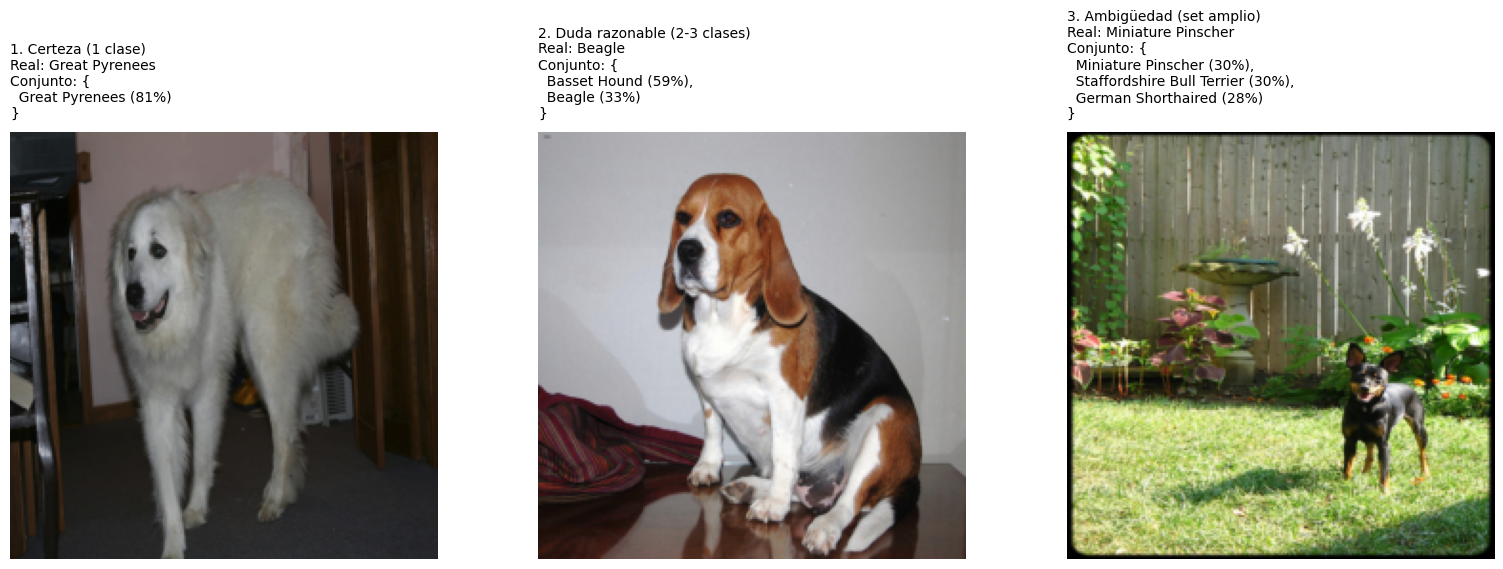

In [11]:
# 7. Selección automática de 3 ejemplos visuales para tu post de Substack
idx_1_candidates = np.where((set_sizes == 1) & hits)[0]
idx_1 = (
    idx_1_candidates[0]
    if len(idx_1_candidates) > 0
    else int(np.argmin(set_sizes))
)

idx_2_candidates = np.where((set_sizes >= 2) & (set_sizes <= 3) & hits)[0]
idx_2 = idx_2_candidates[0] if len(idx_2_candidates) > 0 else 1

idx_3_candidates = np.where(set_sizes >= 4)[0]
idx_3 = (
    idx_3_candidates[0] if len(idx_3_candidates) > 0 else int(np.argmax(set_sizes))
)

ejemplos = [
    ("1. Certeza (1 clase)", idx_1),
    ("2. Duda razonable (2-3 clases)", idx_2),
    ("3. Ambigüedad (set amplio)", idx_3),
]


def unnormalize(tensor_img):
  img = tensor_img.permute(1, 2, 0).numpy()
  img = img * np.array(STD) + np.array(MEAN)
  return np.clip(img, 0, 1)


fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for ax, (titulo_caso, idx) in zip(axes, ejemplos):
  img_tensor, true_idx = test_dataset[idx]
  pred_indices = prediction_sets[idx]
  probs = probs_test[idx]

  pred_indices = pred_indices[np.argsort(-probs[pred_indices])]
  etiquetas_set = [f"{class_names[i]} ({probs[i]:.0%})" for i in pred_indices]

  ax.imshow(unnormalize(img_tensor))
  ax.axis("off")
  set_str = (
      "{\n  " + ",\n  ".join(etiquetas_set) + "\n}" if etiquetas_set else "{ }"
  )
  ax.set_title(
      f"{titulo_caso}\nReal: {class_names[true_idx]}\nConjunto: {set_str}",
      fontsize=10,
      loc="left",
      pad=10,
  )

  print(f"=== {titulo_caso} ===")
  print(f"Clase real: {class_names[true_idx]}")
  print(
      f"Conjunto de predicción: {[class_names[i] for i in pred_indices]}"
      f" (Tamaño: {len(pred_indices)})\n"
  )

plt.tight_layout()
plt.savefig("conformal_substack_ejemplos.png", dpi=200, bbox_inches="tight")
plt.show()

INFERENCIA CONFORMAL EN IMAGEN PERSONALIZADA: images.jpeg
Umbral calibrado (1 - q_hat, α=0.1): 25.71%
Longitud del intervalo conformal : 2 categoría(s)
Intervalo / Conjunto predicho   : {Chihuahua (36.22%), Shiba Inu (27.34%)}

Top-10 probabilidades asignadas por el modelo:
   1. Chihuahua                    -> 36.22%  [✓ EN CONJUNTO]
   2. Shiba Inu                    -> 27.34%  [✓ EN CONJUNTO]
   3. Miniature Pinscher           ->  8.71%  [  fuera]
   4. Pomeranian                   ->  7.94%  [  fuera]
   5. Beagle                       ->  5.59%  [  fuera]
   6. American Pit Bull Terrier    ->  2.65%  [  fuera]
   7. Basset Hound                 ->  2.49%  [  fuera]
   8. Abyssinian                   ->  1.56%  [  fuera]
   9. Staffordshire Bull Terrier   ->  0.96%  [  fuera]
  10. Yorkshire Terrier            ->  0.90%  [  fuera]



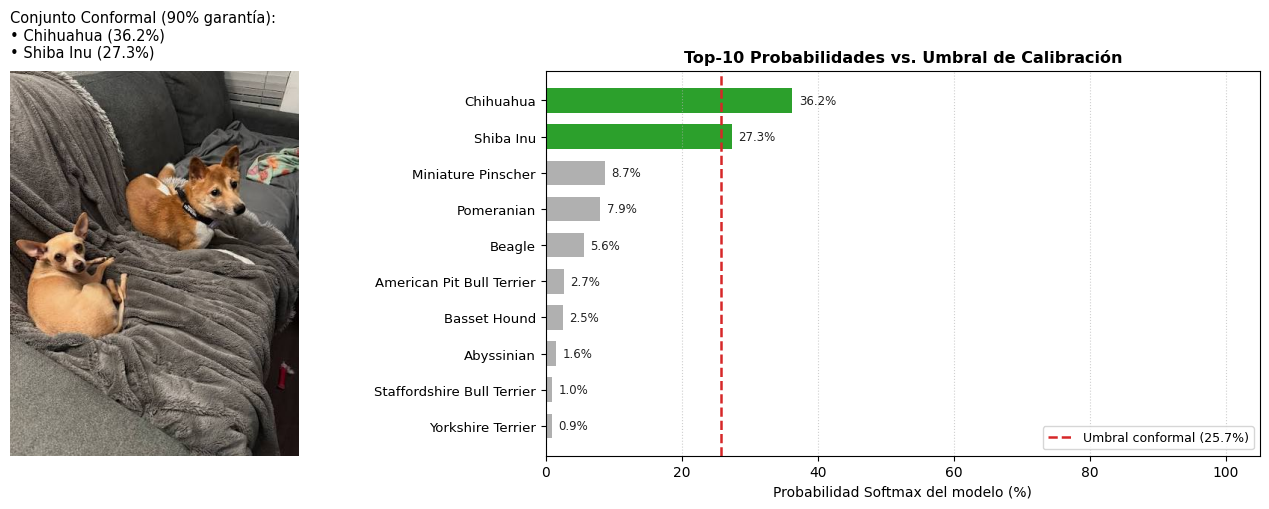

In [15]:
# 8. Predicción Conformal sobre imagen personalizada (cat-and-yorkie-350x263-1920w.jpg)
CUSTOM_IMG_PATH = "images.jpeg"

# Si ejecutas en Google Colab y el archivo aún no está en la carpeta actual, permite subirlo
if not os.path.exists(CUSTOM_IMG_PATH):
  try:
    from google.colab import files
    print(f"No se encontró '{CUSTOM_IMG_PATH}'. Selecciónalo para subirlo:")
    uploaded = files.upload()
    CUSTOM_IMG_PATH = next(iter(uploaded.keys()))
  except ImportError:
    raise FileNotFoundError(
        f"Coloca '{CUSTOM_IMG_PATH}' en el mismo directorio que el script."
    )

custom_img = Image.open(CUSTOM_IMG_PATH).convert("RGB")
input_tensor = transform(custom_img).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
  probs_custom = F.softmax(model(input_tensor), dim=1).squeeze(0).cpu().numpy()

# Conjunto conformal (clases cuya probabilidad >= 1 - q_hat)
custom_set_idx = np.where(probs_custom >= prob_threshold)[0]
custom_set_idx = custom_set_idx[np.argsort(-probs_custom[custom_set_idx])]

# Top-10 probabilidades del modelo para inspeccionar cómo reparte la confianza
top10_idx = np.argsort(-probs_custom)[:10]

print("=" * 62)
print(f"INFERENCIA CONFORMAL EN IMAGEN PERSONALIZADA: {CUSTOM_IMG_PATH}")
print("=" * 62)
print(f"Umbral calibrado (1 - q_hat, α={ALPHA}): {prob_threshold:.2%}")
print(
    f"Longitud del intervalo conformal : {len(custom_set_idx)} categoría(s)"
)

if len(custom_set_idx) > 0:
  set_formatted = [
      f"{class_names[i]} ({probs_custom[i]:.2%})" for i in custom_set_idx
  ]
  print(f"Intervalo / Conjunto predicho   : {{{', '.join(set_formatted)}}}")
else:
  print(
      "Intervalo / Conjunto predicho   : { } (Conjunto vacío: ninguna clase"
      f" alcanza el umbral de {prob_threshold:.2%})"
  )

print("\nTop-10 probabilidades asignadas por el modelo:")
for rank, idx_c in enumerate(top10_idx, start=1):
  in_set = "✓ EN CONJUNTO" if probs_custom[idx_c] >= prob_threshold else "  fuera"
  print(
      f"  {rank:2d}. {class_names[idx_c]:<28} -> {probs_custom[idx_c]:6.2%}"
      f"  [{in_set}]"
  )
print("=" * 62 + "\n")

# Visualización de la imagen y sus probabilidades vs. umbral conformal
fig, (ax_img, ax_bar) = plt.subplots(
    1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.35]}
)

ax_img.imshow(custom_img)
ax_img.axis("off")
if len(custom_set_idx) > 0:
  set_title_lines = "\n".join(
      [f"• {class_names[i]} ({probs_custom[i]:.1%})" for i in custom_set_idx]
  )
  titulo_pred = (
      f"Conjunto Conformal ({target_coverage:.0%} garantía):\n{set_title_lines}"
  )
else:
  titulo_pred = (
      f"Conjunto Conformal ({target_coverage:.0%} garantía):\n{{ }} (Abstención:"
      " ambigüedad alta)"
  )
ax_img.set_title(titulo_pred, fontsize=10.5, loc="left", pad=10)

top10_names = [class_names[i] for i in top10_idx]
top10_probs_pct = probs_custom[top10_idx] * 100
bar_colors_custom = [
    "#2ca02c" if p >= prob_threshold * 100 else "#b0b0b0" for p in top10_probs_pct
]

y_bars = np.arange(len(top10_idx))
bars = ax_bar.barh(y_bars, top10_probs_pct, color=bar_colors_custom, height=0.68)
ax_bar.axvline(
    prob_threshold * 100,
    color="#d62728",
    linestyle="--",
    linewidth=1.8,
    label=f"Umbral conformal ({prob_threshold:.1%})",
)

for bar, pct in zip(bars, top10_probs_pct):
  ax_bar.text(
      pct + 1.0,
      bar.get_y() + bar.get_height() / 2,
      f"{pct:.1f}%",
      va="center",
      fontsize=8.5,
      color="#222222",
  )

ax_bar.set_yticks(y_bars)
ax_bar.set_yticklabels(top10_names, fontsize=9.5)
ax_bar.invert_yaxis()
ax_bar.set_xlim(0, max(105, np.max(top10_probs_pct) + 12))
ax_bar.set_xlabel("Probabilidad Softmax del modelo (%)", fontsize=10)
ax_bar.set_title(
    "Top-10 Probabilidades vs. Umbral de Calibración",
    fontsize=11.5,
    fontweight="bold",
)
ax_bar.grid(axis="x", linestyle=":", alpha=0.6)
ax_bar.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig("conformal_imagen_personalizada.png", dpi=200, bbox_inches="tight")
plt.show()